# Neural network with one hidden layer (NumPy)

Planar classification: a linear model vs a network with one tanh hidden layer.
The implementation is in `model.py` (tested in `test_model.py`);
this notebook contains experiments and plots only.

In [39]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data import make_flower, make_sklearn_dataset, plot_decision_boundary
from model import ShallowNetwork
from sklearn.linear_model import LogisticRegression as SkLogReg


In [45]:
DRIVE_ASSETS = Path("/content/drive/MyDrive/data/01-foundations/shallow-network/assets")
LOCAL_ASSETS = Path("../assets")

ASSETS = DRIVE_ASSETS if Path("/content/drive/MyDrive").exists() else LOCAL_ASSETS
ASSETS.mkdir(parents=True, exist_ok=True)
print("Saving assets to:", ASSETS.resolve())

Saving assets to: /content/drive/MyDrive/data/01-foundations/shallow-network/assets


## 1. Data

X_train: (2, 400) | Y_train: (1, 400) | X_test: (2, 200)


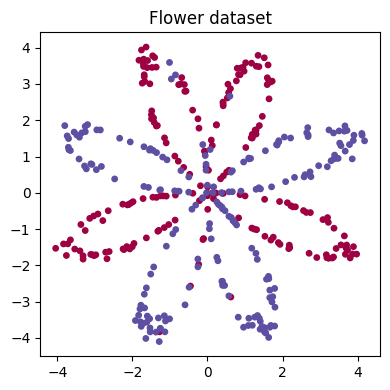

In [46]:
X_train, Y_train = make_flower(400, seed=1)
X_test, Y_test = make_flower(200, seed=2)
print("X_train:", X_train.shape, "| Y_train:", Y_train.shape, "| X_test:", X_test.shape)

plt.figure(figsize=(4, 4))
plt.scatter(X_train[0], X_train[1], c=Y_train.ravel(), s=15, cmap=plt.cm.Spectral)
plt.title("Flower dataset")
plt.tight_layout()
plt.savefig(ASSETS / "dataset.png", dpi=150)
plt.show()

## 2. Baseline: linear classifier

logistic regression: train 52.8% | test 47.0%


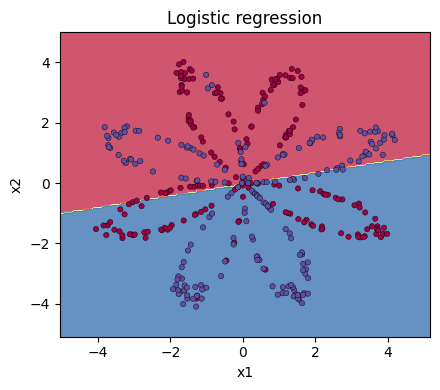

In [47]:
lin = SkLogReg().fit(X_train.T, Y_train.ravel())
lin_fn = lambda P: lin.predict(P.T).reshape(1, -1)
lin_train = lin.score(X_train.T, Y_train.ravel())
lin_test = lin.score(X_test.T, Y_test.ravel())
print(f"logistic regression: train {lin_train:.1%} | test {lin_test:.1%}")

plt.figure(figsize=(4.5, 4))
plot_decision_boundary(lin_fn, X_train, Y_train)
plt.title("Logistic regression")
plt.tight_layout()
plt.savefig(ASSETS / "boundary_linear.png", dpi=150)
plt.show()

## 3. Network with 4 hidden units

hidden=4: train 94.5% | test 93.0%


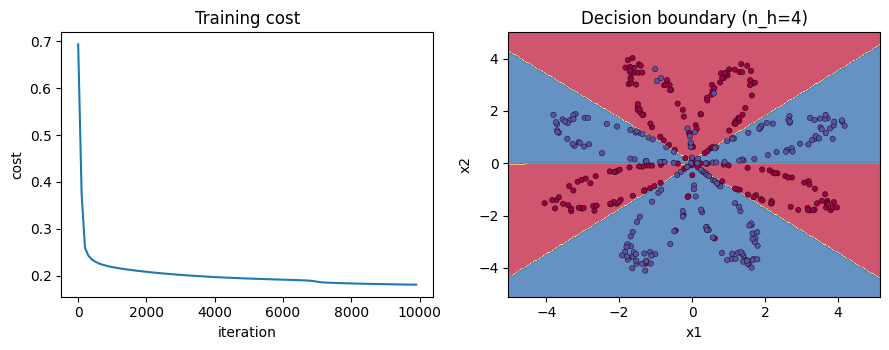

In [48]:
net = ShallowNetwork(n_hidden=4, learning_rate=1.2, num_iterations=10000, log_every=100).fit(X_train, Y_train)
print(f"hidden=4: train {net.score(X_train, Y_train):.1%} | test {net.score(X_test, Y_test):.1%}")

fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
axes[0].plot(np.arange(len(net.costs_)) * net.log_every, net.costs_)
axes[0].set_xlabel("iteration")
axes[0].set_ylabel("cost")
axes[0].set_title("Training cost")
plot_decision_boundary(net.predict, X_train, Y_train, ax=axes[1])
axes[1].set_title("Decision boundary (n_h=4)")
plt.tight_layout()
plt.savefig(ASSETS / "boundary_nh4.png", dpi=150)
plt.show()

## 4. Effect of the hidden layer size

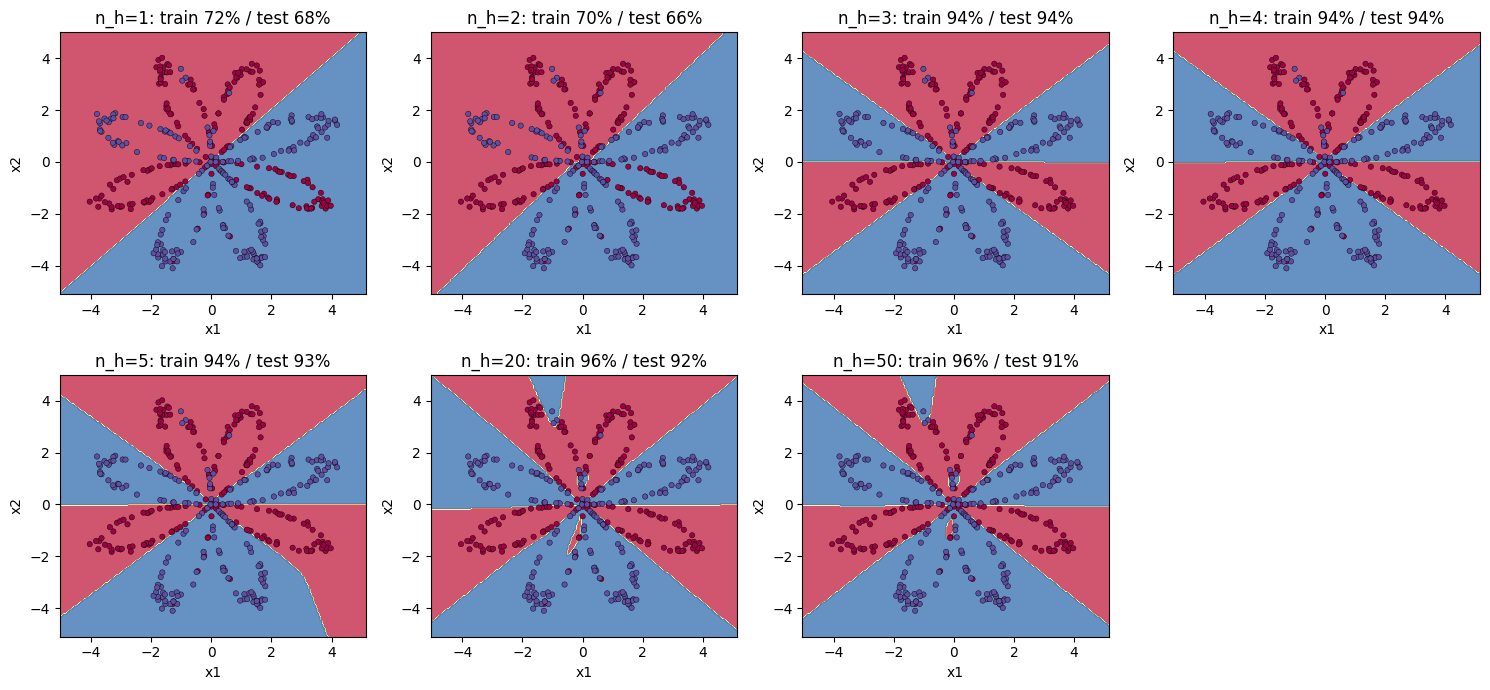

n_h | train | test
  1 | 71.5% | 67.5%
  2 | 70.5% | 65.5%
  3 | 93.5% | 93.5%
  4 | 93.5% | 93.5%
  5 | 93.5% | 93.0%
 20 | 96.5% | 92.0%
 50 | 95.5% | 91.0%


In [ ]:
sizes = [1, 2, 3, 4, 5, 20, 50]
fig, axes = plt.subplots(2, 4, figsize=(15, 7))
rows = []
for ax, n_h in zip(axes.ravel(), sizes):
    m: ShallowNetwork = ShallowNetwork(n_hidden=n_h, num_iterations=5000).fit(X_train, Y_train)
    tr, te = m.score(X_train, Y_train), m.score(X_test, Y_test)
    rows.append((n_h, tr, te))
    plot_decision_boundary(m.predict, X_train, Y_train, ax=ax)
    ax.set_title(f"n_h={n_h}: train {tr:.0%} / test {te:.0%}")
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(ASSETS / "hidden_sizes.png", dpi=150)
plt.show()

print("n_h | train | test")
for n_h, tr, te in rows:
    print(f"{n_h:>3} | {tr:.1%} | {te:.1%}")

## 5. Other datasets

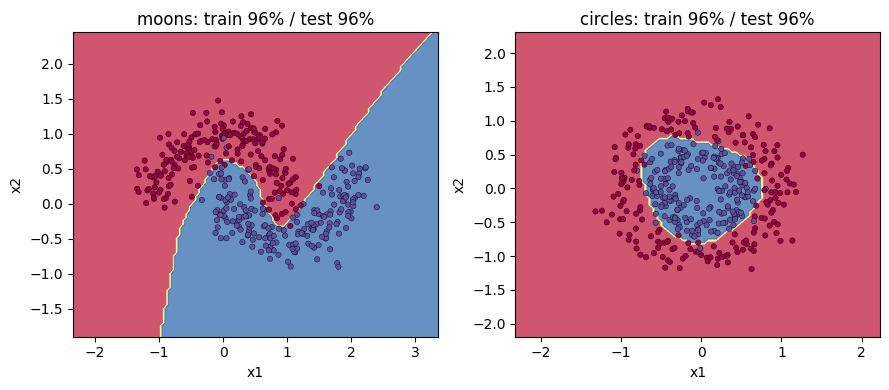

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, name in zip(axes, ["moons", "circles"]):
    Xd, Yd = make_sklearn_dataset(name, 400, seed=0)
    Xt, Yt = make_sklearn_dataset(name, 200, seed=1)
    m = ShallowNetwork(n_hidden=4, num_iterations=5000).fit(Xd, Yd)
    plot_decision_boundary(m.predict, Xd, Yd, ax=ax)
    ax.set_title(f"{name}: train {m.score(Xd, Yd):.0%} / test {m.score(Xt, Yt):.0%}")
plt.tight_layout()
plt.savefig(ASSETS / "other_datasets.png", dpi=150)
plt.show()

## 6. Results and notes

- **Linear vs network:** logistic regression is at chance level (train 52.8%, test 47.0%)
  because the flower classes are not linearly separable. A network with 4 hidden units
  reaches 94.5% train / 93.0% test. The hidden layer with a nonlinear activation (tanh)
  lets the model build a nonlinear decision boundary; without the nonlinearity, any number
  of layers would still collapse into a linear model. 

- **Hidden size:** with 1-2 units the model underfits (train ~71%, test ~66%): both errors are
  high. At 3 units it jumps to 93.5% / 93.5%, and 4-5 units give the same result, so 3-4
  units are enough. Beyond that train accuracy rises (96.5% at 20 units) while test accuracy
  slowly falls (92.0% at 20, 91.0% at 50), a sign of mild overfitting to noise.

- **Train/test gap:** 0 points at n_h=3-4, 4.5 points at both n_h=20 and n_h=50. The test
  accuracy at 50 units is 1 point lower than at 20, which is 2 images out of 200, so this
  difference alone is within noise; the trend across 4 → 20 → 50 is what matters.
  (Note: the n_h=4 run in section 3 used 10000 iterations, the sweep used 5000, hence
  94.5/93.0 vs 93.5/93.5.) 

- **Activations:** tanh in the hidden layer adds the nonlinearity and, unlike sigmoid, has
  zero-centered outputs in (-1, 1), which usually makes gradient descent behave better.
  Sigmoid at the output maps the score to a probability in (0, 1), which matches the
  cross-entropy cost; the class is then chosen with a 0.5 threshold.